In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

print("Loading classification dataset...")
df_clf = pd.read_csv('claffication_Loan_default.csv', low_memory=False)

print("Shape of Data:", df_clf.shape)
print("\n--- Info ---")
df_clf.info()
display(df_clf.head())

Loading classification dataset...
Shape of Data: (255347, 18)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str 

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
df_dirty = df_clf.copy()

symbols = ['*', '?', '&', '%', '$', '#', '@']
np.random.seed(42)

for col in ['Income', 'CreditScore']:
    df_dirty[col] = df_dirty[col].astype(object)
    mask = np.random.rand(len(df_dirty)) < 0.05
    df_dirty.loc[mask, col] = np.random.choice(symbols, size=mask.sum())

print("Dirty Data Sample (Notice the symbols):")
display(df_dirty[['Income', 'CreditScore']].sample(5, random_state=42))

print("\nCleaning data...")

df_clean = df_dirty.drop(columns=['LoanID'], errors='ignore').copy()

df_clean = df_clean.replace(symbols, np.nan)

numeric_cols = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 
                'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Default']

for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
    
cat_cols = ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 
            'HasDependents', 'LoanPurpose', 'HasCoSigner']
for col in cat_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print(f"Total missing values left: {df_clean.isnull().sum().sum()}")

Dirty Data Sample (Notice the symbols):


,Income,CreditScore
51139,112656,581
71005,91569,641
35684,78169,569
174087,63033,326
137952,29665,662



Cleaning data...
Total missing values left: 0


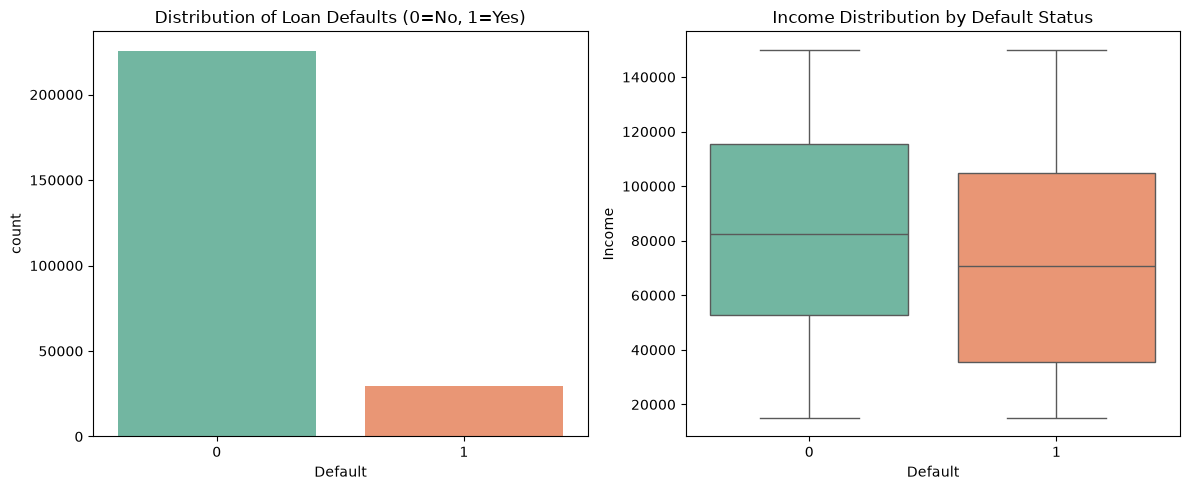

In [4]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df_clean, x='Default', palette='Set2')
plt.title('Distribution of Loan Defaults (0=No, 1=Yes)')

plt.subplot(1, 2, 2)
sns.boxplot(data=df_clean, x='Default', y='Income', palette='Set2')
plt.title('Income Distribution by Default Status')

plt.tight_layout()
plt.show()

X = df_clean.drop(columns=['Default'])
y = df_clean['Default'].astype(int) # Ensure target is integer

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print("Training shape after preprocessing:", X_train_p.shape)

Training shape after preprocessing: (204277, 31)


Training Logistic Regression...
Training Random Forest Classifier (Optimized for speed)...

--- Logistic Regression ---
Accuracy: 0.8852
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45139
           1       0.61      0.03      0.06      5931

    accuracy                           0.89     51070
   macro avg       0.75      0.52      0.50     51070
weighted avg       0.85      0.89      0.84     51070


--- Random Forest ---
Accuracy: 0.8843
              precision    recall  f1-score   support

           0       0.88      1.00      0.94     45139
           1       0.73      0.01      0.01      5931

    accuracy                           0.88     51070
   macro avg       0.81      0.50      0.48     51070
weighted avg       0.87      0.88      0.83     51070



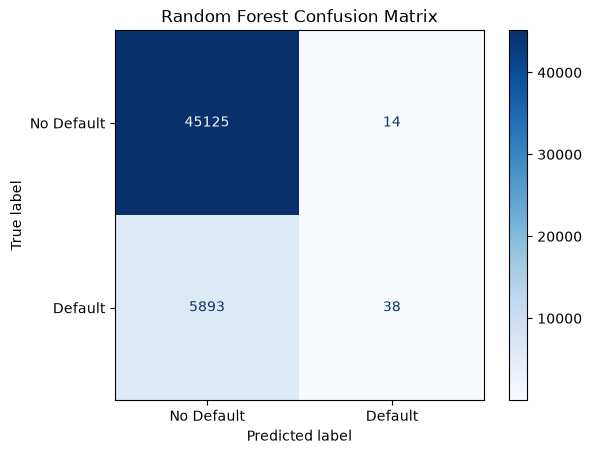

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Training Logistic Regression...")
log_model = LogisticRegression(max_iter=500)
log_model.fit(X_train_p, y_train)

print("Training Random Forest Classifier (Optimized for speed)...")
rf_model = RandomForestClassifier(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_p, y_train)

log_preds = log_model.predict(X_test_p)
rf_preds = rf_model.predict(X_test_p)

print("\n--- Logistic Regression ---")
print(f"Accuracy: {accuracy_score(y_test, log_preds):.4f}")
print(classification_report(y_test, log_preds))

print("\n--- Random Forest ---")
print(f"Accuracy: {accuracy_score(y_test, rf_preds):.4f}")
print(classification_report(y_test, rf_preds))

cm = confusion_matrix(y_test, rf_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default', 'Default'])
disp.plot(cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.show()

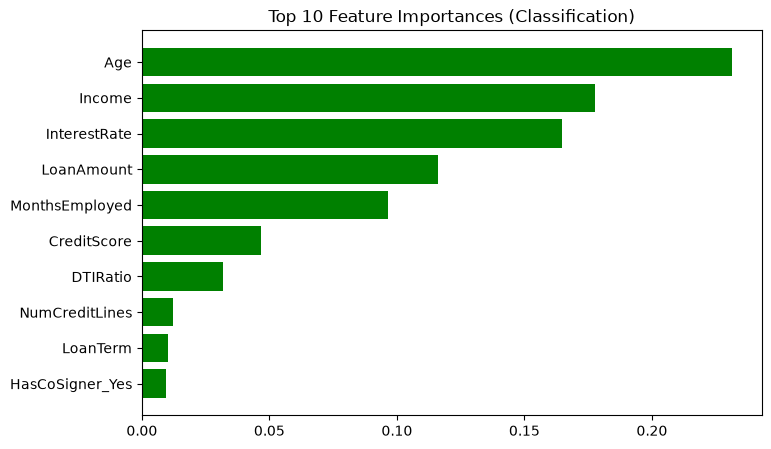

5-Fold CV Accuracy Scores: [0.88498629 0.88530448 0.88459185 0.88542406 0.8852772 ]
Mean CV Accuracy: 0.8851


In [7]:
from sklearn.model_selection import cross_val_score

cat_encoded_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features))
feature_names = numeric_features + cat_encoded_names
importances = rf_model.feature_importances_

indices = np.argsort(importances)[-10:]
plt.figure(figsize=(8, 5))
plt.barh(range(len(indices)), importances[indices], align="center", color='green')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.title("Top 10 Feature Importances (Classification)")
plt.show()

cv_scores = cross_val_score(log_model, X_train_p, y_train, cv=5, scoring='accuracy')
print(f"5-Fold CV Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")

In [8]:
joblib.dump(rf_model, 'rf_loan_classifier.pkl')
joblib.dump(preprocessor, 'loan_preprocessor.pkl')
print("Model and Preprocessor saved to disk.")

demo_data = pd.DataFrame([{
    'Age': 25,
    'Income': 35000,
    'LoanAmount': 150000,
    'CreditScore': 450,
    'MonthsEmployed': 12,
    'NumCreditLines': 5,
    'InterestRate': 18.5,
    'LoanTerm': 60,
    'DTIRatio': 0.65,
    'Education': 'High School',
    'EmploymentType': 'Unemployed',
    'MaritalStatus': 'Single',
    'HasMortgage': 'No',
    'HasDependents': 'Yes',
    'LoanPurpose': 'Business',
    'HasCoSigner': 'No'
}])

loaded_prep = joblib.load('loan_preprocessor.pkl')
loaded_model = joblib.load('rf_loan_classifier.pkl')

demo_processed = loaded_prep.transform(demo_data)
prediction = loaded_model.predict(demo_processed)[0]
probability = loaded_model.predict_proba(demo_processed)[0]

print(f"\n--- LIVE DEMO PREDICTION ---")
if prediction == 1:
    print(f"Result: DEFAULT PREDICTED! (Probability: {probability[1]*100:.1f}%)")
else:
    print(f"Result: SAFE (Will Pay)  (Probability: {probability[0]*100:.1f}%)")

Model and Preprocessor saved to disk.

--- LIVE DEMO PREDICTION ---
Result: SAFE (Will Pay)  (Probability: 69.6%)
